> **Version formatrice.** Tous les exercices sont complétés et le notebook a été exécuté. Les participants utilisent la version à compléter, à la racine du dossier.

# IA102 — Notebook 5 — Introduction à l'entraînement haute performance

**Durée : 30 minutes** · Objectif visé : **O4** — s'initier à l'entraînement haute performance

Les entraînements réels durent des heures ou des jours, sur des données volumineuses. Ce notebook présente les leviers qui permettent d'exploiter efficacement un GPU et une grappe de calcul de l'Alliance.

| Levier | Question | Section |
| --- | --- | --- |
| Mesure du débit | Combien d'images par seconde le modèle traite-t-il ? | 1 |
| Chargement des données | Le GPU attend-il les données ? | 2 |
| Précision mixte | Peut-on calculer en 16 bits sans perdre en exactitude ? | 3 |
| Points de contrôle | Comment reprendre un entraînement interrompu ? | 4 |
| Parallélisme de données (DDP) | Comment répartir l'entraînement sur plusieurs GPU ? | 5 |
| Soumission Slurm | Comment lancer et suivre un entraînement sur une grappe ? | 6 |

Les démonstrations s'exécutent sur processeur ou sur GPU. Les gains les plus importants (précision mixte, multi-GPU) ne se mesurent que sur GPU : relancez ce notebook sur un nœud GPU pour les observer.

In [1]:
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [2]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DOSSIER_DONNEES = os.environ.get("IA102_DONNEES", "donnees")
appareil = "cuda" if torch.cuda.is_available() else "cpu"
print("Appareil :", appareil, "| cœurs disponibles :", os.cpu_count())
if appareil == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))

def cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(32 * 7 * 7, 64), nn.ReLU(), nn.Linear(64, 10))
perte_fn = nn.CrossEntropyLoss()

Appareil : cpu | cœurs disponibles : 2


## 1. Mesurer le débit

Avant d'optimiser, on **mesure**. L'indicateur de base est le **débit** : le nombre d'exemples traités par seconde pendant l'entraînement.

Sur GPU, les opérations sont **asynchrones** : il faut appeler `torch.cuda.synchronize()` avant de lire l'horloge, sans quoi la mesure est faussée.

**Prédiction.** Comment le débit évolue-t-il avec la taille des lots ?

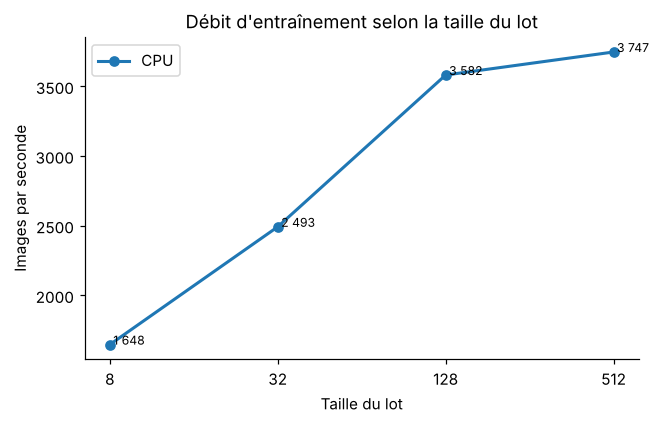

In [3]:
def debit(taille_lot, appareil_mesure=appareil, n_exemples=4096):
    torch.manual_seed(0)
    m = cnn().to(appareil_mesure); opt = torch.optim.Adam(m.parameters())
    x = torch.randn(taille_lot, 1, 28, 28, device=appareil_mesure); y = torch.randint(0, 10, (taille_lot,), device=appareil_mesure)
    for _ in range(3):                                          # itérations d'échauffement
        opt.zero_grad(); perte_fn(m(x), y).backward(); opt.step()
    if appareil_mesure == "cuda": torch.cuda.synchronize()
    n_iter = max(2, n_exemples // taille_lot); debut = time.time()
    for _ in range(n_iter):
        opt.zero_grad(); perte_fn(m(x), y).backward(); opt.step()
    if appareil_mesure == "cuda": torch.cuda.synchronize()
    return n_iter * taille_lot / (time.time() - debut)

tailles = [8, 32, 128, 512]
resultats = {"CPU": [debit(t, "cpu") for t in tailles]}
if torch.cuda.is_available():
    resultats["GPU"] = [debit(t, "cuda") for t in tailles]

plt.figure(figsize=(6.5, 3.8))
for nom, valeurs in resultats.items():
    plt.plot(tailles, valeurs, "o-", lw=2, label=nom)
    for t, v in zip(tailles, valeurs): plt.text(t, v, f" {v:,.0f}".replace(",", " "), fontsize=8)
plt.xscale("log", base=2); plt.xticks(tailles, [str(t) for t in tailles]); plt.xlabel("Taille du lot"); plt.ylabel("Images par seconde")
plt.title("Débit d'entraînement selon la taille du lot"); plt.legend(); plt.show()

Le débit augmente avec la taille des lots jusqu'à la saturation du matériel : sur processeur, le plafond est atteint rapidement ; sur GPU, l'augmentation est beaucoup plus marquée, car des milliers d'unités de calcul travaillent en parallèle. Deux limites :
- la **mémoire** du GPU (une erreur `CUDA out of memory` indique un lot trop grand) ;
- l'**optimisation** : avec des lots plus grands, on effectue moins de mises à jour par époque, et il faut souvent ajuster le taux d'apprentissage (règle empirique : l'augmenter proportionnellement à la taille du lot, avec une phase de montée progressive).

## 2. Le chargement des données

Un GPU traite des milliers d'images par seconde ; si la lecture et la transformation des images sont faites par un seul cœur, le GPU **attend**. Trois réglages du `DataLoader` :

| Réglage | Effet |
| --- | --- |
| `num_workers=k` | Prépare les lots dans `k` processus parallèles (un par cœur réservé) |
| `pin_memory=True` | Place les lots dans une mémoire qui accélère le transfert vers le GPU |
| `persistent_workers=True` | Conserve les processus entre les époques |

Sur les grappes de l'Alliance, copiez aussi les données sur le **disque local du nœud** (`$SLURM_TMPDIR`) : la lecture y est beaucoup plus rapide que sur les systèmes de fichiers partagés (`/project`, `/scratch`), surtout pour de nombreux petits fichiers.

### Exercice 11 — Paralléliser le chargement

Mesurez le temps nécessaire pour parcourir 6000 images augmentées, avec 0 puis 2 processus de chargement.

**Corrigé**

In [4]:
augmentation = transforms.Compose([transforms.RandomRotation(10), transforms.RandomAffine(0, translate=(0.1, 0.1)), transforms.ToTensor()])
donnees = Subset(datasets.FashionMNIST(DOSSIER_DONNEES, train=True, download=True, transform=augmentation), range(6000))

for n_processus in [0, 2]:
    chargeur = DataLoader(donnees, batch_size=128, num_workers=n_processus, pin_memory=(appareil == "cuda"))
    debut = time.time()
    for images, etiquettes in chargeur:
        pass
    print(f"num_workers = {n_processus} : {time.time() - debut:.2f} s")

num_workers = 0 : 1.45 s


num_workers = 2 : 1.01 s


Le gain est proportionnel au nombre de cœurs disponibles. Sur une grappe, réservez des cœurs avec `--cpus-per-task` et utilisez la même valeur pour `num_workers` (variable `$SLURM_CPUS_PER_TASK`).

**Diagnostic :** pendant un entraînement, `nvidia-smi` affiche le taux d'utilisation du GPU. Une utilisation faible ou en dents de scie signale généralement un goulot d'étranglement dans le chargement des données.

## 3. La précision mixte

Par défaut, les calculs se font en **32 bits** (`float32`). Les GPU récents disposent d'unités spécialisées (Tensor Cores) beaucoup plus rapides en **16 bits**. La **précision mixte automatique** (AMP) exécute en 16 bits les opérations qui le tolèrent (convolutions, produits matriciels) et conserve en 32 bits celles qui exigent de la précision (sommes, pertes).

| Format | Bits | Usage |
| --- | --- | --- |
| `float32` | 32 | Référence |
| `float16` | 16 | GPU ; nécessite une mise à l'échelle de la perte (`GradScaler`) pour éviter que de petits gradients s'annulent |
| `bfloat16` | 16 | GPU récents (A100, H100) ; même plage de valeurs que `float32`, pas de mise à l'échelle nécessaire |

Gains typiques sur GPU : entraînement 1,5 à 3 fois plus rapide et mémoire réduite, pour une exactitude équivalente.

In [5]:
def pas_entrainement(modele, optimiseur, x, y, precision_mixte, mise_a_echelle=None):
    optimiseur.zero_grad()
    if precision_mixte:
        type_16 = torch.float16 if appareil == "cuda" else torch.bfloat16
        with torch.autocast(device_type=appareil, dtype=type_16):    # calculs en 16 bits lorsque c'est sûr
            perte = perte_fn(modele(x), y)
    else:
        perte = perte_fn(modele(x), y)
    if mise_a_echelle is not None:                                   # float16 sur GPU
        mise_a_echelle.scale(perte).backward(); mise_a_echelle.step(optimiseur); mise_a_echelle.update()
    else:
        perte.backward(); optimiseur.step()
    return perte.item()

x = torch.randn(256, 1, 28, 28, device=appareil); y = torch.randint(0, 10, (256,), device=appareil)
for precision_mixte in [False, True]:
    torch.manual_seed(0)
    m = cnn().to(appareil); opt = torch.optim.Adam(m.parameters())
    echelle = torch.amp.GradScaler("cuda") if (precision_mixte and appareil == "cuda") else None
    for _ in range(3): pas_entrainement(m, opt, x, y, precision_mixte, echelle)
    if appareil == "cuda": torch.cuda.synchronize()
    debut = time.time()
    for _ in range(20): perte = pas_entrainement(m, opt, x, y, precision_mixte, echelle)
    if appareil == "cuda": torch.cuda.synchronize()
    print(f"Précision mixte {'activée ' if precision_mixte else 'désactivée'} : {(time.time() - debut) / 20 * 1000:.1f} ms par lot | perte {perte:.3f}")
if appareil == "cpu":
    print("Sur processeur, la précision mixte n'accélère pas le calcul : cette cellule illustre la syntaxe. Le gain apparaît sur GPU.")

Précision mixte désactivée : 50.1 ms par lot | perte 1.669


Précision mixte activée  : 71.1 ms par lot | perte 1.675
Sur processeur, la précision mixte n'accélère pas le calcul : cette cellule illustre la syntaxe. Le gain apparaît sur GPU.


## 4. Les points de contrôle

Sur une grappe, chaque tâche a une **durée maximale** (`--time`). Un entraînement long doit donc pouvoir **reprendre** là où il s'est arrêté. On sauvegarde régulièrement un **point de contrôle** contenant tout l'état nécessaire : paramètres du modèle, état de l'optimiseur (les moyennes d'Adam), numéro d'époque.

### Exercice 12 — Sauvegarder et reprendre

**Corrigé**

In [6]:
torch.manual_seed(0)
modele = cnn(); optimiseur = torch.optim.Adam(modele.parameters(), lr=1e-3)
epoque_terminee = 3

point_de_controle = {
    "epoque": epoque_terminee,
    "modele": modele.state_dict(),
    "optimiseur": optimiseur.state_dict(),
}
torch.save(point_de_controle, "point_de_controle.pt")

modele_repris = cnn(); optimiseur_repris = torch.optim.Adam(modele_repris.parameters(), lr=1e-3)
etat = torch.load("point_de_controle.pt", map_location="cpu")
modele_repris.load_state_dict(etat["modele"])
optimiseur_repris.load_state_dict(etat["optimiseur"])
epoque_depart = etat["epoque"] + 1
print("Reprise à l'époque", epoque_depart)
print("Paramètres identiques :", all(torch.equal(a, b) for a, b in zip(modele.state_dict().values(), modele_repris.state_dict().values())))

Reprise à l'époque 4
Paramètres identiques : True


## 5. L'entraînement sur plusieurs GPU : `DistributedDataParallel`

Le **parallélisme de données** est la stratégie multi-GPU la plus courante :

```
                 Lot global de 256 images
          ┌──────────────┼──────────────┐
      GPU 0 (rang 0)   GPU 1 (rang 1)   …         chaque processus a une copie complète du modèle
      64 images        64 images                  et reçoit une partie différente des données
      passe avant      passe avant
      rétropropagation rétropropagation
          └──── all-reduce : moyenne des gradients ────┘
      mise à jour      mise à jour                identique sur chaque GPU : les copies restent synchronisées
```

Mise en œuvre dans PyTorch :
1. lancer **un processus par GPU** avec `torchrun` ;
2. initialiser la communication : `dist.init_process_group(backend="nccl")` (`gloo` sur processeur) ;
3. envelopper le modèle : `DDP(modele, device_ids=[rang_local])` ;
4. répartir les données avec un `DistributedSampler` (et appeler `sampler.set_epoch(epoque)` à chaque époque) ;
5. ne sauvegarder et n'afficher que depuis le **rang 0**.

Le script suivant applique ces étapes. On le lance ici avec deux processus sur processeur, ce qui simule deux GPU.

In [7]:
%%writefile entrainer_ddp.py
"""Entraînement multi-GPU avec DistributedDataParallel. Lancement : torchrun --nproc_per_node=<nb GPU> entrainer_ddp.py"""
import os, time, argparse
import torch, torch.nn as nn, torch.distributed as dist
from torch.utils.data import DataLoader, Subset
from torch.utils.data.distributed import DistributedSampler
from torch.nn.parallel import DistributedDataParallel as DDP
from torchvision import datasets, transforms

parser = argparse.ArgumentParser()
parser.add_argument("--donnees", default="donnees")
parser.add_argument("--epoques", type=int, default=1)
parser.add_argument("--lot", type=int, default=64, help="taille du lot PAR processus")
parser.add_argument("--limite", type=int, default=0, help="nombre d'images utilisées (0 = toutes)")
parser.add_argument("--workers", type=int, default=0)
args = parser.parse_args()

# 1-2. Un processus par GPU ; torchrun fournit RANK, LOCAL_RANK et WORLD_SIZE
dist.init_process_group(backend="nccl" if torch.cuda.is_available() else "gloo")
rang, nb_processus = dist.get_rank(), dist.get_world_size()
rang_local = int(os.environ.get("LOCAL_RANK", 0))
if torch.cuda.is_available():
    torch.cuda.set_device(rang_local)
appareil = torch.device(f"cuda:{rang_local}" if torch.cuda.is_available() else "cpu")

# 4. Chaque processus reçoit une partie distincte des données
donnees = datasets.FashionMNIST(args.donnees, train=True, transform=transforms.ToTensor())
if args.limite:
    donnees = Subset(donnees, range(args.limite))
echantillonneur = DistributedSampler(donnees, shuffle=True)
chargeur = DataLoader(donnees, batch_size=args.lot, sampler=echantillonneur, num_workers=args.workers, pin_memory=torch.cuda.is_available())

# 3. Copie du modèle sur chaque GPU, gradients moyennés automatiquement
torch.manual_seed(0)
modele = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(32 * 7 * 7, 64), nn.ReLU(), nn.Linear(64, 10)).to(appareil)
modele = DDP(modele, device_ids=[rang_local] if torch.cuda.is_available() else None)
optimiseur = torch.optim.Adam(modele.parameters(), lr=1e-3)
perte_fn = nn.CrossEntropyLoss()

for epoque in range(args.epoques):
    echantillonneur.set_epoch(epoque)           # mélange différent à chaque époque
    debut = time.time()
    for x, y in chargeur:
        x, y = x.to(appareil, non_blocking=True), y.to(appareil, non_blocking=True)
        optimiseur.zero_grad(); perte = perte_fn(modele(x), y); perte.backward(); optimiseur.step()
    print(f"[rang {rang}/{nb_processus}] époque {epoque + 1} : {len(chargeur)} lots en {time.time() - debut:.1f} s", flush=True)

# 5. Sauvegarde par le rang 0 uniquement
if rang == 0:
    torch.save(modele.module.state_dict(), "cnn_ddp.pt")
    print("Modèle sauvegardé par le rang 0.")
dist.destroy_process_group()

Writing entrainer_ddp.py


**Prédiction.** Avec deux processus, combien de lots chaque processus traite-t-il, par rapport à un seul processus ?

In [8]:
commande = (f"OMP_NUM_THREADS=1 {sys.executable} -m torch.distributed.run --nnodes=1 --rdzv-backend=c10d "
            f"--rdzv-endpoint=127.0.0.1:29512 --nproc_per_node={{n}} entrainer_ddp.py --donnees {DOSSIER_DONNEES} --limite 12000 2>&1 | grep -v socket")
for n in [1, 2]:
    print(f"--- {n} processus ---")
    get_ipython().system(commande.format(n=n))

--- 1 processus ---


[rang 0/1] époque 1 : 188 lots en 6.3 s
Modèle sauvegardé par le rang 0.


--- 2 processus ---


[rang 0/2] époque 1 : 94 lots en 4.7 s
[rang 1/2] époque 1 : 94 lots en 4.7 s
Modèle sauvegardé par le rang 0.


Chaque processus traite la moitié des lots : le temps par époque diminue, sans changer l'algorithme. Sur une grappe, chaque processus utilise son propre GPU et la communication passe par NCCL. Le **lot effectif** est la taille du lot par processus multipliée par le nombre de processus (ici 2 × 64 = 128).

Au-delà d'un nœud, ou pour des modèles trop grands pour la mémoire d'un GPU, d'autres stratégies existent (FSDP, parallélisme de modèle), hors du cadre de cet atelier.

## 6. Soumettre l'entraînement avec Slurm

Sur une grappe, on décrit les ressources nécessaires dans un script, et l'ordonnanceur **Slurm** lance la tâche dès que les ressources sont disponibles.

| Option `#SBATCH` | Rôle | Recommandation |
| --- | --- | --- |
| `--account` | Compte du groupe de recherche (`def-...`, `rrg-...`) | Obligatoire |
| `--gpus-per-node` | Nombre de GPU par nœud | Commencer par 1 ; vérifier le gain avant d'en demander davantage |
| `--cpus-per-task` | Cœurs pour le chargement des données | Environ 4 à 8 par GPU ; même valeur pour `num_workers` |
| `--mem` | Mémoire vive | Ajuster d'après `seff` après un premier essai |
| `--time` | Durée maximale | Estimation réaliste : les tâches courtes démarrent plus tôt |
| `--output` | Fichier de sortie (`%x` : nom, `%j` : numéro de tâche) | Un fichier par tâche |

### Exercice 13 — Script de soumission pour un GPU

Demandez 1 GPU, 4 cœurs, 16 Go de mémoire et 30 minutes.

**Corrigé**

In [9]:
%%writefile soumettre_un_gpu.sh
#!/bin/bash
#SBATCH --job-name=cnn-fashion
#SBATCH --account=def-VOTRE_GROUPE
#SBATCH --gpus-per-node=1
#SBATCH --cpus-per-task=4
#SBATCH --mem=16G
#SBATCH --time=00:30:00
#SBATCH --output=%x-%j.out

module load python/3.11                     # vérifier les versions disponibles : module avail python

# Environnement virtuel sur le disque local du nœud, paquets fournis par l'Alliance
virtualenv --no-download $SLURM_TMPDIR/env
source $SLURM_TMPDIR/env/bin/activate
pip install --no-index --upgrade pip
pip install --no-index torch torchvision

# Données copiées sur le disque local du nœud
cp -r ~/scratch/donnees $SLURM_TMPDIR/

torchrun --standalone --nproc_per_node=1 entrainer_ddp.py \
    --donnees $SLURM_TMPDIR/donnees --epoques 10 --workers $SLURM_CPUS_PER_TASK

Writing soumettre_un_gpu.sh


Pour **quatre GPU sur un nœud**, seules quelques lignes changent :

In [10]:
%%writefile soumettre_quatre_gpu.sh
#!/bin/bash
#SBATCH --job-name=cnn-fashion-ddp
#SBATCH --account=def-VOTRE_GROUPE
#SBATCH --nodes=1
#SBATCH --gpus-per-node=4
#SBATCH --ntasks-per-node=1
#SBATCH --cpus-per-task=16                  # 4 cœurs par GPU
#SBATCH --mem=64G
#SBATCH --time=01:00:00
#SBATCH --output=%x-%j.out

module load python/3.11
virtualenv --no-download $SLURM_TMPDIR/env && source $SLURM_TMPDIR/env/bin/activate
pip install --no-index torch torchvision
cp -r ~/scratch/donnees $SLURM_TMPDIR/

torchrun --standalone --nproc_per_node=4 entrainer_ddp.py \
    --donnees $SLURM_TMPDIR/donnees --epoques 10 --workers 4

Writing soumettre_quatre_gpu.sh


### Commandes essentielles

| Commande | Rôle |
| --- | --- |
| `sbatch soumettre_un_gpu.sh` | Soumettre la tâche |
| `squeue -u $USER` | Suivre ses tâches (en attente, en cours) |
| `scancel <numéro>` | Annuler une tâche |
| `seff <numéro>` | Après la tâche : mémoire et temps réellement utilisés |
| `salloc --gpus-per-node=1 --cpus-per-task=4 --mem=16G --time=1:00:00 --account=def-VOTRE_GROUPE` | Session interactive sur un nœud GPU, pour la mise au point |
| `nvidia-smi` (dans la tâche) | Utilisation et mémoire du GPU |

### Bonnes pratiques

1. **Tester en petit** avant de soumettre (1 époque, sous-ensemble des données, session `salloc`).
2. **Copier les données** sur `$SLURM_TMPDIR` ; regrouper les nombreux petits fichiers dans une archive.
3. **Télécharger à l'avance** données et poids préentraînés : les nœuds de calcul n'ont pas accès à Internet.
4. **Sauvegarder des points de contrôle** pour pouvoir reprendre après la limite de temps.
5. **Vérifier l'utilisation du GPU** (`nvidia-smi`) avant de demander plus de GPU ; un GPU sous-utilisé n'accélère rien.
6. **Ajuster les ressources** demandées d'après `seff` : une demande juste réduit l'attente et préserve les allocations du groupe.

---

## Synthèse de l'atelier : test de positionnement final

In [11]:
quiz("1. Que calcule un neurone artificiel ?",
     ["Il mémorise une image", "Une combinaison linéaire de ses entrées, plus un biais, suivie d'une activation", "La classe la plus probable"],
     1, "a = φ(wᵀx + b).")

**Question de vérification.** 1. Que calcule un neurone artificiel ?

RadioButtons(layout=Layout(width='max-content'), options=('Il mémorise une image', "Une combinaison linéaire d…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

In [12]:
quiz("2. Pourquoi une fonction d'activation non linéaire est-elle nécessaire ?",
     ["Pour accélérer les calculs", "Sans elle, un empilement de couches équivaut à une seule couche linéaire", "Pour réduire le nombre de paramètres"],
     1, "La composition de fonctions affines reste affine.")

**Question de vérification.** 2. Pourquoi une fonction d'activation non linéaire est-elle nécessaire ?

RadioButtons(layout=Layout(width='max-content'), options=('Pour accélérer les calculs', 'Sans elle, un empilem…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

In [13]:
quiz("3. Quel est l'ordre de la boucle d'entraînement ?",
     ["passe avant, perte, zero_grad, backward, step", "passe avant, backward, perte, step, zero_grad", "zero_grad, step, passe avant, perte, backward"],
     0, "Prédire, mesurer l'erreur, réinitialiser les gradients, rétropropager, mettre à jour.")

**Question de vérification.** 3. Quel est l'ordre de la boucle d'entraînement ?

RadioButtons(layout=Layout(width='max-content'), options=('passe avant, perte, zero_grad, backward, step', 'pa…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

In [14]:
quiz("4. Pourquoi un réseau convolutif convient-il aux images ?",
     ["Ses filtres partagés détectent un motif à toute position, avec peu de paramètres", "Il convertit les images en texte", "Il ne fonctionne que sur GPU"],
     0, "Connectivité locale et partage des poids.")

**Question de vérification.** 4. Pourquoi un réseau convolutif convient-il aux images ?

RadioButtons(layout=Layout(width='max-content'), options=('Ses filtres partagés détectent un motif à toute pos…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

In [15]:
quiz("5. L'utilisation du GPU est de 30 % pendant l'entraînement. Quelle est l'action la plus pertinente ?",
     ["Demander davantage de GPU", "Augmenter num_workers (et --cpus-per-task) et copier les données sur $SLURM_TMPDIR", "Réduire la taille des lots"],
     1, "Le GPU attend les données : il faut accélérer le chargement avant d'ajouter des GPU.")

**Question de vérification.** 5. L'utilisation du GPU est de 30 % pendant l'entraînement. Quelle est l'action la plus pertinente ?

RadioButtons(layout=Layout(width='max-content'), options=('Demander davantage de GPU', 'Augmenter num_workers …

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

### Synthèse des objectifs

| Objectif annoncé | Ce que vous avez réalisé |
| --- | --- |
| O1 — Comprendre les bases de l'apprentissage profond | Neurone, activations, rétropropagation calculée à la main et vérifiée avec autograd (notebooks 0 et 1) |
| O2 — Créer des réseaux de neurones | `nn.Sequential`, `nn.Module`, choix de la sortie et de la perte, réseau convolutif (notebooks 1 et 3) |
| O3 — Entraîner des modèles avec PyTorch | Boucle d'entraînement, optimiseurs, `DataLoader`, régularisation, transfert d'apprentissage (notebooks 2, 3 et 4) |
| O4 — S'initier à l'entraînement haute performance | Débit, chargement parallèle, précision mixte, points de contrôle, DDP, scripts Slurm (notebooks 3 et 5) |

### Évaluation de l'atelier

Merci de répondre au formulaire d'évaluation transmis par Calcul Québec. Indiquez en particulier ce que vous comptez appliquer dans vos propres projets.

### Pour aller plus loin
- **Notebook bonus :** `bonus_transformers.ipynb` — le mécanisme d'attention, au cœur des grands modèles de langage.
- [Tutoriels PyTorch](https://pytorch.org/tutorials/) et [documentation de `DistributedDataParallel`](https://pytorch.org/docs/stable/notes/ddp.html)
- [Documentation technique de l'Alliance](https://docs.alliancecan.ca) : pages PyTorch, Slurm et apprentissage machine.
- L'aide-mémoire IA102, fourni avec les notebooks.